<a href="https://colab.research.google.com/github/darsanipriya-13/Anulakshmi-Divine/blob/main/Copy_of_World_energy_consumption.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print(df.head())

Saving World_Energy_By_Country_And_Region_1965_to_2023.csv to World_Energy_By_Country_And_Region_1965_to_2023.csv
Dataset loaded successfully!
Shape: (111, 60)
               Country   1965   1966   1967   1968   1969   1970   1971  \
0                  NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
1               Canada   5.00   5.32   5.57   5.92   6.28   6.73   6.94   
2               Mexico   1.06   1.12   1.14   1.24   1.36   1.45   1.53   
3                   US  51.98  54.89  56.80  60.19  63.30  65.54  66.92   
4  Total North America  58.04  61.33  63.51  67.36  70.95  73.72  75.39   

    1972   1973  ...    2014    2015    2016    2017    2018    2019    2020  \
0    NaN    NaN  ...     NaN     NaN     NaN     NaN     NaN     NaN     NaN   
1   7.47   8.11  ...   14.43   14.47   14.34   14.54   14.72   14.64   13.76   
2   1.69   1.82  ...    8.03    7.94    8.11    8.26    8.15    8.07    7.35   
3  70.25  73.22  ...   93.59   92.69   92.62   92.97   96.37   95.68 

In [ ]:
# Remove empty rows and clean country names
df = df.dropna(subset=["Country"])
df["Country"] = df["Country"].astype(str).str.strip()

# Select India
country = "India"
row = df[df["Country"] == country]

if row.empty:
    raise ValueError("Selected country not found!")

# Convert year columns into numerical values
years = [c for c in df.columns if str(c).isdigit()]

energy = pd.to_numeric(
    row.iloc[0][years], errors="coerce"
)

# Convert wide format to chronological format
data = pd.DataFrame({
    "Year": years,
    "Energy": energy.values
})

data["Year"] = data["Year"].astype(int)
data = data.sort_values("Year").reset_index(drop=True)

# Handle missing values
data["Energy"] = data["Energy"].interpolate(
    limit_direction="both"
)

data = data.dropna(subset=["Energy"])

print(data.head())
print(data.tail())
print("Number of yearly records:", len(data))
print("Missing values:", data["Energy"].isna().sum())

   Year  Energy
0  1965    2.23
1  1966    2.30
2  1967    2.37
3  1968    2.53
4  1969    2.81
    Year  Energy
54  2019   33.54
55  2020   31.78
56  2021   34.51
57  2022   36.37
58  2023   39.02
Number of yearly records: 59
Missing values: 0


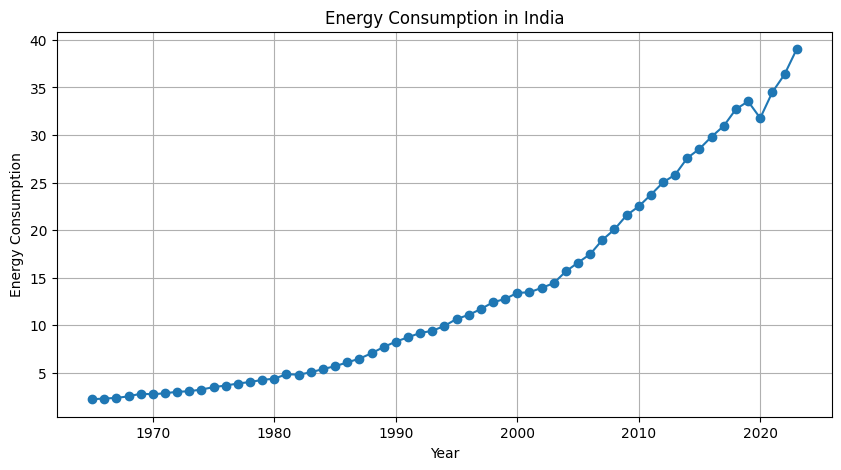

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(data["Year"], data["Energy"], marker="o")

plt.title("Energy Consumption in India")
plt.xlabel("Year")
plt.ylabel("Energy Consumption")
plt.grid(True)
plt.show()

In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Use the first 80% of yearly observations for training
split_index = int(len(data) * 0.8)

scaler = MinMaxScaler(feature_range=(0, 1))

# Fit only on training-period data to prevent leakage
scaler.fit(data[["Energy"]].iloc[:split_index])

scaled_energy = scaler.transform(data[["Energy"]])

print("Original values:")
print(data["Energy"].head())

print("Normalized values:")
print(scaled_energy[:5])

Original values:
0    2.23
1    2.30
2    2.37
3    2.53
4    2.81
Name: Energy, dtype: float64
Normalized values:
[[0.        ]
 [0.00325581]
 [0.00651163]
 [0.01395349]
 [0.02697674]]


In [ ]:
X = []
y = []
target_years = []

for i in range(5, len(scaled_energy)):
    X.append(scaled_energy[i-5:i])
    y.append(scaled_energy[i])
    target_years.append(data["Year"].iloc[i])

X = np.array(X)
y = np.array(y)
target_years = np.array(target_years)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("First 5-year input:", X[0].flatten())
print("First target year:", target_years[0])

X shape: (54, 5, 1)
y shape: (54, 1)
First 5-year input: [0.         0.00325581 0.00651163 0.01395349 0.02697674]
First target year: 1970


In [ ]:
train_mask = target_years < data["Year"].iloc[split_index]

X_train = X[train_mask]
y_train = y[train_mask]

X_test = X[~train_mask]
y_test = y[~train_mask]

years_test = target_years[~train_mask]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Test years:", years_test)

Training samples: 42
Testing samples: 12
Test years: [2012 2013 2014 2015 2016 2017 2018 2019 2020 2021 2022 2023]


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input

model = Sequential([
    Input(shape=(5, 1)),
    LSTM(32, activation="tanh"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=8,
    verbose=1
)

Epoch 1/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.1879
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1375
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0988 
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0665 
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0434 
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0280 
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0206 
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0181 
Epoch 9/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0169 
Epoch 10/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0149 
Epoch 11/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0117 
Epoch 12/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0092 
Epoch 13/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0073 
Epoch 14/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0056 
Epoch 15/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0042 
Epoch 16/100
6/6 ━━━

In [ ]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

# Predict normalized energy values
pred_scaled = model.predict(X_test)

# Convert predictions and targets to original scale
y_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

y_predicted = scaler.inverse_transform(
    pred_scaled
).flatten()

# Calculate evaluation metrics
mae = mean_absolute_error(y_actual, y_predicted)

rmse = np.sqrt(
    mean_squared_error(y_actual, y_predicted)
)

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 538ms/step
MAE: 2.9976
RMSE: 3.3241


    Year  Actual  Predicted
0   2012   25.02  26.165001
1   2013   25.84  27.745001
2   2014   27.59  29.296000
3   2015   28.55  30.768000
4   2016   29.83  32.313000
5   2017   30.96  33.826000
6   2018   32.72  35.279999
7   2019   33.54  36.877998
8   2020   31.78  38.277000
9   2021   34.51  39.410000
10  2022   36.37  40.369999
11  2023   39.02  41.374001


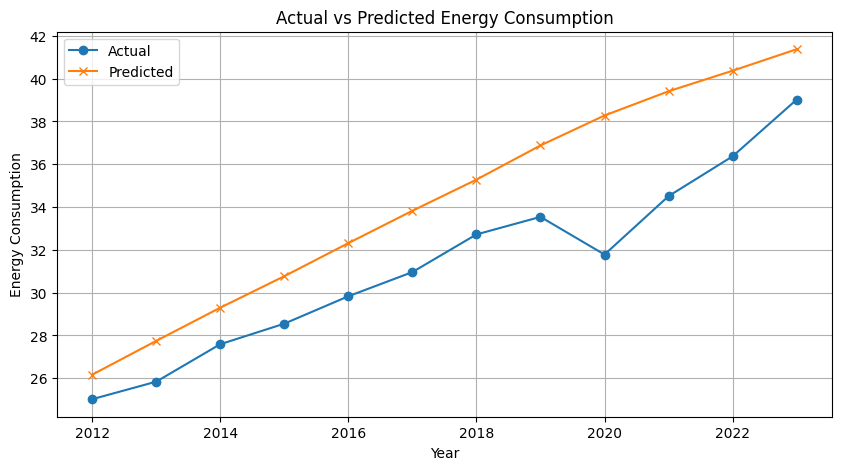

In [ ]:
results = pd.DataFrame({
    "Year": years_test,
    "Actual": y_actual,
    "Predicted": y_predicted
})

print(results.round(3))

plt.figure(figsize=(10, 5))
plt.plot(results["Year"], results["Actual"],
         marker="o", label="Actual")
plt.plot(results["Year"], results["Predicted"],
         marker="x", label="Predicted")

plt.title("Actual vs Predicted Energy Consumption")
plt.xlabel("Year")
plt.ylabel("Energy Consumption")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
last_five_years = scaled_energy[-5:].reshape(1, 5, 1)

next_scaled = model.predict(last_five_years)

next_energy = scaler.inverse_transform(
    next_scaled
)

print("Predicted energy consumption for 2024:",
      round(next_energy[0][0], 3))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 292ms/step
Predicted energy consumption for 2024: 42.352
